Dataset Loaded Successfully


,rownames,Gunnel,Time,Fromlow,Slope,Rw,Amphiso,Subst,Pool,Water,Cobble
0,1,0,786,190,10,0.1,0,3,0,0,0
1,2,0,794,182,10,0.0,0,3,0,0,0
2,3,0,798,178,20,0.0,0,1,0,0,0
3,4,0,800,176,70,0.3,0,1,0,1,0
4,5,0,804,172,40,0.3,0,1,0,1,0


Number of Rows: 1592
Number of Columns: 11
Numeric Columns:
['rownames', 'Gunnel', 'Time', 'Fromlow', 'Slope', 'Rw', 'Amphiso', 'Subst', 'Pool', 'Water', 'Cobble']
Missing Values:
rownames    0
Gunnel      0
Time        0
Fromlow     0
Slope       0
Rw          0
Amphiso     0
Subst       0
Pool        0
Water       0
Cobble      0
dtype: int64
Scaled Data:


,rownames,Gunnel,Time,Fromlow,Slope,Rw,Amphiso,Subst,Pool,Water,Cobble
0,-1.730963,-0.176318,0.594623,0.491201,0.031239,-1.014074,-0.516487,-0.037866,-0.503531,-1.017745,-0.485824
1,-1.728787,-0.176318,0.653528,0.394392,0.031239,-1.251521,-0.516487,-0.037866,-0.503531,-1.017745,-0.485824
2,-1.726611,-0.176318,0.682981,0.345987,0.660769,-1.251521,-0.516487,-0.755524,-0.503531,-1.017745,-0.485824
3,-1.724435,-0.176318,0.697707,0.321784,3.808418,-0.539179,-0.516487,-0.755524,-0.503531,0.982564,-0.485824
4,-1.722259,-0.176318,0.727160,0.273379,1.919829,-0.539179,-0.516487,-0.755524,-0.503531,0.982564,-0.485824
5,-1.720083,-0.176318,0.756613,0.224975,3.178888,-0.539179,-0.516487,-0.755524,-0.503531,0.982564,-0.485824


PCA Completed
Explained Variance Ratio:
[0.20304697 0.16837527 0.14422721 0.096891   0.09046842 0.08264374
 0.0695467  0.05326448 0.04583435 0.03848208 0.00721976]
Total Explained Variance:
1.0
PCA Summary:


,Principal_Component,Standard_Deviation,Variance_Percentage,Cumulative_Percentage
0,PC1,1.494965,20.304697,20.304697
1,PC2,1.361357,16.837527,37.142224
2,PC3,1.259959,14.422721,51.564945
3,PC4,1.032701,9.689100,61.254045
4,PC5,0.997887,9.046842,70.300888
5,PC6,0.953757,8.264374,78.565261
6,PC7,0.874925,6.954670,85.519932
7,PC8,0.765688,5.326448,90.846380
8,PC9,0.710278,4.583435,95.429816
9,PC10,0.650822,3.848208,99.278024


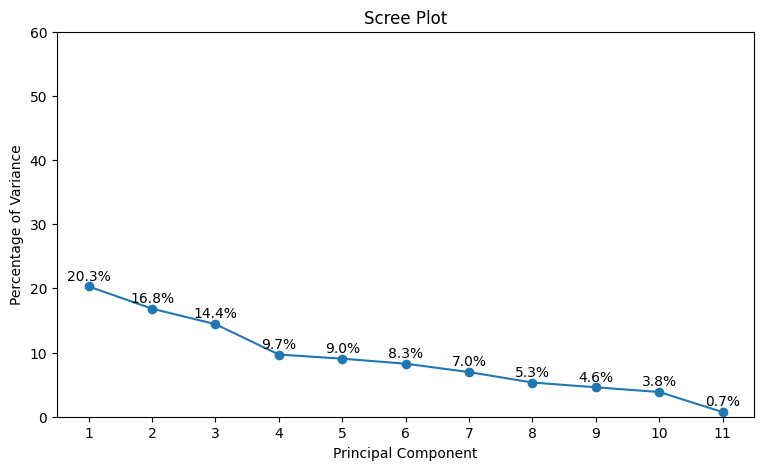

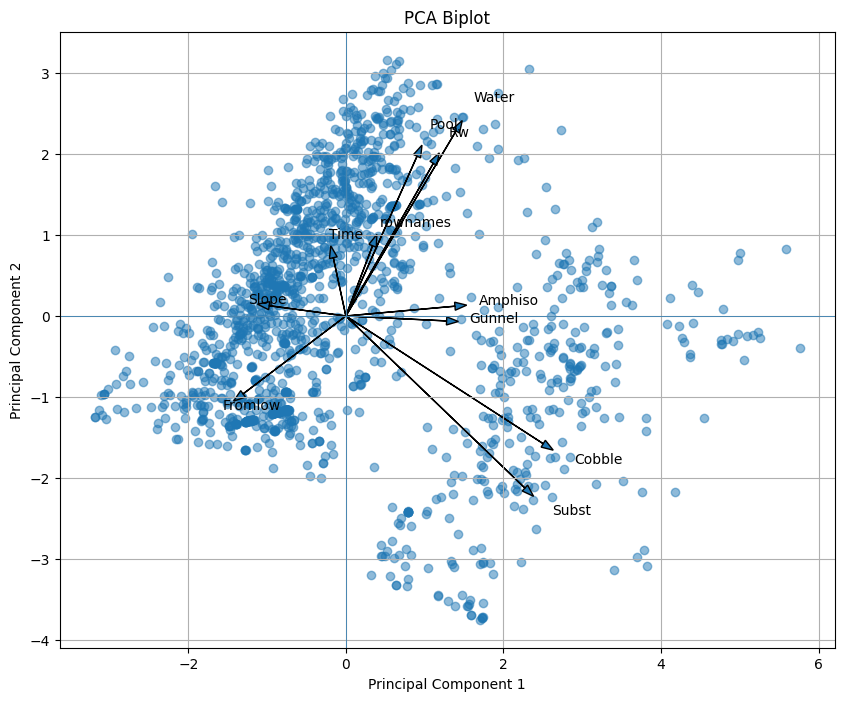

First Six PCA Scores:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
0,-1.427356,-1.295073,-0.205490,-0.337053,0.317898,-0.372933,-0.045243,1.509565,0.180974,0.025334,0.142508
1,-1.458192,-1.359805,-0.158644,-0.277758,0.371552,-0.450959,-0.025151,1.585643,0.008880,0.135451,0.104090
2,-1.928536,-1.005656,-0.459858,-0.337274,0.628182,-0.046399,0.027640,1.528104,-0.192589,0.152442,-0.339909
3,-1.868158,0.348412,-1.491906,-1.375096,2.470843,1.940414,-0.514936,0.655004,-0.414225,1.484196,0.124440
4,-1.431567,0.308795,-0.945228,-1.045983,1.482900,0.729330,-0.290711,1.004612,0.140802,1.374411,-0.063355
5,-1.701232,0.361424,-1.308871,-1.242842,2.114404,1.554084,-0.464642,0.823539,-0.278937,1.468897,0.058322


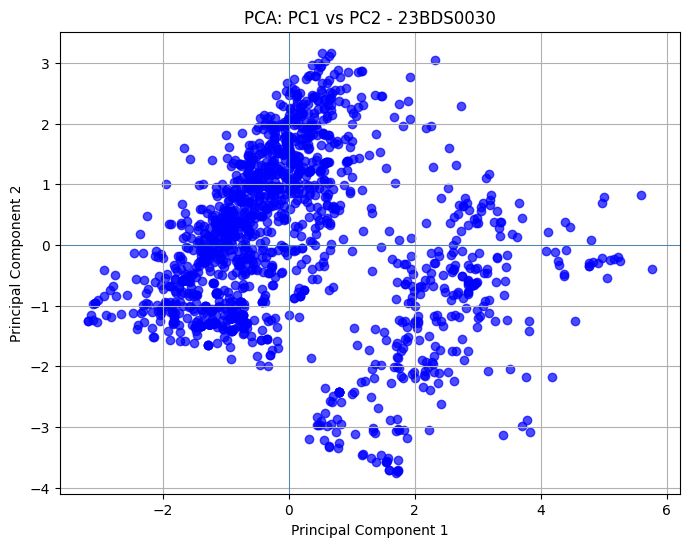

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ASSESSMENT 9
# PRINCIPAL COMPONENT ANALYSIS

# 1. Load Dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Gunnels.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")

display(df.head())

# 2. Display Number of Rows and Columns
print(
    "Number of Rows:",
    df.shape[0]
)

print(
    "Number of Columns:",
    df.shape[1]
)

# 3. Extract Numeric Columns and Normalize
numeric_data = df.select_dtypes(
    include=np.number
).copy()

print("Numeric Columns:")
print(
    numeric_data.columns.tolist()
)

# Check missing values
print("Missing Values:")
print(
    numeric_data.isnull().sum()
)

# Remove missing rows
numeric_data = numeric_data.dropna()

# Standardize data
scaler = StandardScaler()

data_scaled = scaler.fit_transform(
    numeric_data
)

data_scaled = pd.DataFrame(
    data_scaled,
    columns=numeric_data.columns
)

print("Scaled Data:")
display(
    data_scaled.head(6)
)

# 4. Perform PCA
pca = PCA()

pca_result = pca.fit_transform(
    data_scaled
)

print("PCA Completed")

print(
    "Explained Variance Ratio:"
)

print(
    pca.explained_variance_ratio_
)

print(
    "Total Explained Variance:"
)

print(
    np.sum(
        pca.explained_variance_ratio_
    )
)

# PCA Summary
summary = pd.DataFrame({
    "Principal_Component": [
        f"PC{i+1}"
        for i in range(
            len(
                pca.explained_variance_ratio_
            )
        )
    ],

    "Standard_Deviation":
        np.sqrt(
            pca.explained_variance_
        ),

    "Variance_Percentage":
        pca.explained_variance_ratio_
        * 100,

    "Cumulative_Percentage":
        np.cumsum(
            pca.explained_variance_ratio_
        ) * 100
})

print("PCA Summary:")
display(summary)

# 5. Scree Plot
variance_percentage = (
    pca.explained_variance_ratio_
    * 100
)

components = np.arange(
    1,
    len(
        variance_percentage
    ) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    components,
    variance_percentage,
    marker="o"
)

for x, y in zip(
    components,
    variance_percentage
):

    plt.text(
        x,
        y + 1,
        f"{y:.1f}%",
        ha="center"
    )

plt.title(
    "Scree Plot"
)

plt.xlabel(
    "Principal Component"
)

plt.ylabel(
    "Percentage of Variance"
)

plt.ylim(
    0,
    60
)

plt.xticks(
    components
)

plt.show()

# 6. PCA Biplot
pca_2 = PCA(
    n_components=2
)

scores_2 = pca_2.fit_transform(
    data_scaled
)

loadings = (
    pca_2.components_.T
)

plt.figure(figsize=(10, 8))

plt.scatter(
    scores_2[:, 0],
    scores_2[:, 1],
    alpha=0.5
)

for i, feature in enumerate(
    numeric_data.columns
):

    plt.arrow(
        0,
        0,
        loadings[i, 0] * 5,
        loadings[i, 1] * 5,
        head_width=0.1,
        length_includes_head=True
    )

    plt.text(
        loadings[i, 0] * 5.5,
        loadings[i, 1] * 5.5,
        feature
    )

plt.axhline(
    0,
    linewidth=0.5
)

plt.axvline(
    0,
    linewidth=0.5
)

plt.title(
    "PCA Biplot"
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.grid()

plt.show()

# 7. Extract PCA Scores
column_names = [
    f"PC{i+1}"
    for i in range(
        pca_result.shape[1]
    )
]

pca_scores = pd.DataFrame(
    pca_result,
    columns=column_names
)

print(
    "First Six PCA Scores:"
)

display(
    pca_scores.head(6)
)

# 8. PC1 vs PC2 Scatter Plot
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_scores["PC1"],
    pca_scores["PC2"],
    color="blue",
    marker="o",
    alpha=0.7
)

plt.title(
    "PCA: PC1 vs PC2 - 23BDS0030"
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.axhline(
    0,
    linewidth=0.5
)

plt.axvline(
    0,
    linewidth=0.5
)

plt.grid()

plt.show()